# MindTrack | Phase 2 (Member C): "App-ready" models and feature selection

**Plan of this notebook**

| Step | What we do | Why |
|---|---|---|
| 0 | Load the team's shared train/test split | Everyone must be graded on the same students |
| 1 | Fix the list of inputs the app can really collect | A model is useless in the app if it needs data the app cannot get |
| 2 | Feature selection, part 1: **correlation** | Find inputs that repeat each other, and inputs linked to the target |
| 3 | Build the app-ready models (all inputs vs selected inputs) | Same four models and the same baseline as Members A and B |
| 4 | Honesty checks (confidence range, repeated CV, shuffled labels) | Make sure a score is not luck |
| 5 | Feature selection, part 2: **importance** | See which inputs the models really lean on |
| 6 | Compare with the earlier models (Members A and B) | What did we lose by using only app inputs? |
| 7 | Choose and save the final app-ready model per target | Hand over to Phase 3 (Kotlin export) |

**Analogy for the whole notebook:** Members A and B tested a very large "ingredient list" in the lab. The app is a small kitchen that only has some of those ingredients. My job is to cook the best dish possible with only what the kitchen has, and to check which ingredients actually matter.

**Targets.** `depressed_flag` (Beck total 11 or more) and `dependence_flag` (phone-dependence total 39 or more). Both are *screening flags from self-report questionnaires, not diagnoses.*

## Step 0: Setup and the shared split

*Analogy:* the train set is the textbook we study from and the test set is the exam. The exam is opened **once**, at the end. Both are exactly the files Member C produced in Phase 1 (seed 42), the same ones Members A and B used.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEED = 42

# Works whether you run from the project root or from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from memberC_selector import CorrImportanceSelector     # our feature-selection step (src/memberC_selector.py)

PROC, RES, MOD, DOCS = ROOT / "data" / "processed", ROOT / "results", ROOT / "models", ROOT / "docs"
FIG = DOCS / "figures"
CACHE = ROOT / ".cache_appready"          # speed-up + checkpoints; safe to delete, ignored by git (see .gitignore note)
for p in (RES, MOD, FIG, CACHE):
    p.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(PROC / "train.csv")      # NOT the scaled copies: scaling is done inside each CV fold instead
test = pd.read_csv(PROC / "test.csv")
assert not set(train["code"]) & set(test["code"]), "train and test students overlap!"

TARGETS = {"Depression flag": "depressed_flag", "Dependence flag": "dependence_flag"}
for name, t in TARGETS.items():
    print(f"{name:16s} train {len(train)} ({train[t].sum()} flagged, {train[t].mean():.1%}) | "
          f"test {len(test)} ({test[t].sum()} flagged, {test[t].mean():.1%})")

Depression flag  train 976 (175 flagged, 17.9%) | test 244 (43 flagged, 17.6%)
Dependence flag  train 976 (439 flagged, 45.0%) | test 244 (110 flagged, 45.1%)


## Step 1: Define the inputs the app can collect

You confirmed the app can only collect these (so nothing else is allowed in):

* **About the student:** age, sex, department, semester, family income level, who they live with, urban or rural home
* **About the phone:** phone plan, network type, device type, when they got their first phone, where the phone is mostly used
* **Apps:** the eight "most used app" yes/no flags

**Deliberately left out** (the app cannot ask for them): family-communication/activity items, household phone rules, phone-related arguments, discrimination over phone use, marital status, the posture and ergonomics columns, the daily-use band (its coding looks broken) and, of course, every questionnaire answer (`tmd_*`, `bdi_*`) because the targets are built from them.

*Analogy:* this is the shopping list for the small kitchen. The code below also acts as a **security guard**: if a banned column ever sneaks onto the list, it stops with an error.

In [2]:
ORDERED = ["age", "semester", "ses", "time_first_cellphone"]      # numbers / ordered levels (these get scaled)
APPS = [c for c in train.columns if c.startswith("app_")]         # 8 yes/no flags
DUMMY_PREFIXES = ("department_", "sex_", "living_arrangement_", "residence_area_",
                  "subscription_plan_", "network_access_", "areas_use_", "type_md_")
DUMMIES = [c for c in train.columns if c.startswith(DUMMY_PREFIXES)]   # yes/no columns made in Phase 1 (one-hot)
APP_INPUTS = ORDERED + APPS + DUMMIES

# ---- the security guard -------------------------------------------------------------------------------------
BANNED_PREFIXES = ("tmd_", "bdi_", "marital_status_", "pos_", "time_stand", "time_walk", "time_sit", "time_lying",
                   "family_", "mobile_use_rules", "phone_discrimination", "phone_related_arguments",
                   "avg_daily_use", "usual_phone_location", "primary_input", "frequent_touch", "hand_dominance",
                   "program", "age_group", "code")
banned = [c for c in APP_INPUTS if c.startswith(BANNED_PREFIXES) or "depress" in c or "dependence" in c]
assert not banned, f"Banned columns on the input list: {banned}"
assert len(APP_INPUTS) == len(set(APP_INPUTS)) == 31
print(len(APP_INPUTS), "app inputs:", len(ORDERED), "ordered/numeric,", len(APPS), "app flags,", len(DUMMIES), "yes/no background columns")

# A small, readable table of the inputs (also saved for the report and for Phase 3)
group_of = lambda c: ("Apps" if c.startswith("app_") else
                      "Phone" if c.startswith(("subscription_plan_", "network_access_", "areas_use_", "type_md_")) or c == "time_first_cellphone"
                      else "About the student")
inputs_table = pd.DataFrame({"input": APP_INPUTS, "group": [group_of(c) for c in APP_INPUTS],
                             "kind": ["numeric / ordered (scaled)" if c in ORDERED else "yes/no (0 or 1)" for c in APP_INPUTS]})
inputs_table.to_csv(DOCS / "app_inputs_memberC.csv", index=False)
display(inputs_table.groupby(["group", "kind"]).size().rename("how many").reset_index())

31 app inputs: 4 ordered/numeric, 8 app flags, 19 yes/no background columns


,group,kind,how many
0,About the student,numeric / ordered (scaled),3
1,About the student,yes/no (0 or 1),10
2,Apps,yes/no (0 or 1),8
3,Phone,numeric / ordered (scaled),1
4,Phone,yes/no (0 or 1),9


## Step 2: Feature selection, part 1 (correlation)

Correlation is a number from -1 to +1 that says how much two columns move together. We use it in two different ways:

* **(a) Input vs target.** "Does this input move together with the thing we want to predict?" *Analogy: which ingredients does the dish's flavour actually follow?*
* **(b) Input vs input.** "Are two inputs basically the same information?" *Analogy: two friends who always repeat each other. You only need to listen to one.*

Everything here uses the **training set only**.

Strongest correlations with the targets (note how small they are: nothing above ~0.13)


,Depression flag,Dependence flag,strongest_abs
age,-0.120,-0.124,0.124
type_md_Laptop,-0.068,-0.112,0.112
areas_use_University,0.099,0.005,0.099
department_Engineering,0.099,0.034,0.099
app_social_media,-0.040,-0.088,0.088
living_arrangement_Mother/Father only,0.020,0.081,0.081
ses,0.014,0.080,0.080
residence_area_Urban,-0.033,-0.078,0.078



Pairs of inputs with |correlation| >= 0.8 (near-duplicates):


,input_1,input_2,correlation
2,network_access_Cellular data,network_access_Wi-Fi,-0.986
3,areas_use_Home,areas_use_University,-0.888
1,department_Health,type_md_Smartphone,0.831
0,time_first_cellphone,department_Health,0.817


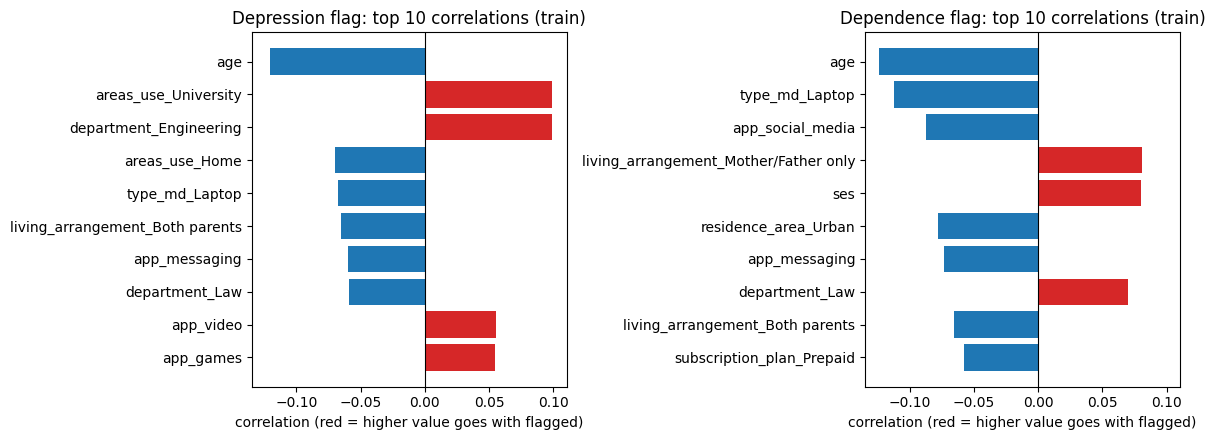

In [3]:
# (a) correlation of every app input with each target (sign shows direction, size shows strength)
corr_target = pd.DataFrame({n: train[APP_INPUTS].corrwith(train[t]) for n, t in TARGETS.items()})
corr_target["strongest_abs"] = corr_target.abs().max(axis=1)
corr_target = corr_target.sort_values("strongest_abs", ascending=False)
corr_target.round(3).to_csv(RES / "phase2_appready_feature_correlation_with_target.csv", index_label="input")
print("Strongest correlations with the targets (note how small they are: nothing above ~0.13)")
display(corr_target.head(8).round(3))

# (b) pairs of inputs that repeat each other
CORR_CUT = 0.8
cm = train[APP_INPUTS].corr()
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(APP_INPUTS) for b in APP_INPUTS[i + 1:] if abs(cm.loc[a, b]) >= CORR_CUT]
redundant = pd.DataFrame(pairs, columns=["input_1", "input_2", "correlation"]).sort_values("correlation", key=abs, ascending=False)
redundant.round(3).to_csv(RES / "phase2_appready_redundant_pairs.csv", index=False)
print(f"\nPairs of inputs with |correlation| >= {CORR_CUT} (near-duplicates):")
display(redundant.round(3))

# chart: top 10 inputs by correlation with each target
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, (n, t) in zip(axes, TARGETS.items()):
    s = corr_target[n].reindex(corr_target[n].abs().sort_values(ascending=False).index).head(10)[::-1]
    ax.barh(s.index, s.values, color=["tab:red" if v > 0 else "tab:blue" for v in s.values])
    ax.axvline(0, color="black", lw=0.8); ax.set_title(f"{n}: top 10 correlations (train)")
    ax.set_xlabel("correlation (red = higher value goes with flagged)")
plt.tight_layout(); plt.savefig(FIG / "appready_correlation_with_targets.png", dpi=130); plt.show()

**What this tells us**

* Every input-to-target correlation is small (all below about 0.13). Early warning: any model built from these inputs will be modest. That fits what Members A and B found.
* A few inputs are near-duplicates (for example, using Wi-Fi and using cellular data). Keeping both adds noise but no new information. The selector in Step 3 removes the weaker of each duplicate pair, **inside** each cross-validation fold so no test information leaks in.

## Step 3: Build the app-ready models

**Same recipe as Members A and B** so the results can be compared fairly: a baseline plus logistic regression, decision tree, random forest and gradient boosting, tuned with 5-fold cross-validation on the training set only, scored by AUC.

I compare **two versions of the inputs**:

| Version | Inputs |
|---|---|
| **All app inputs** | all 31 inputs |
| **Selected** | correlation filter (drop the weaker of near-duplicate pairs) then keep the top *k* by importance, with *k* in {8, 12, 18} chosen by cross-validation |

*Analogy for cross-validation:* split the textbook into 5 parts. Study on 4, quiz yourself on the 5th, rotate 5 times. It tells us how well we learn without peeking at the real exam.

*Analogy for the baseline:* a student who answers "no" to every question. It is the score to beat. For the depression flag (about 18% positive) the baseline looks good on plain accuracy (about 82%) while finding nobody, so we use AUC, recall and balanced accuracy.

*Why a Pipeline:* scaling and selection are learned **inside** each fold from that fold's training part only. Doing them before splitting would be like seeing part of the exam while studying.

In [4]:
SCALE_PATTERN = "^(" + "|".join(ORDERED) + ")$"      # only the 4 numeric columns are scaled; yes/no columns are left alone


def make_pipe(model, selector):
    pre = ColumnTransformer([("scale", StandardScaler(), make_column_selector(pattern=SCALE_PATTERN))],
                            remainder="passthrough")
    return Pipeline([("sel", selector), ("pre", pre), ("m", model)], memory=str(CACHE / "pipe"))


def zoo(variant):
    """The models and the settings we try. 'selected' also tries k = 8, 12 or 18 inputs."""
    selector = CorrImportanceSelector() if variant == "All app inputs" else CorrImportanceSelector(corr_cut=CORR_CUT, seed=SEED)
    extra = {} if variant == "All app inputs" else {"sel__top_k": [8, 12, 18]}
    mk = lambda m: make_pipe(m, selector)
    return {
        "Baseline (most common)": (mk(DummyClassifier(strategy="most_frequent")), {}),
        "Logistic regression": (mk(LogisticRegression(max_iter=3000, class_weight="balanced")),
                                {"m__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1], **extra}),
        "Decision tree": (mk(DecisionTreeClassifier(class_weight="balanced", random_state=SEED)),
                          {"m__max_depth": [2, 3, 4, 5], "m__min_samples_leaf": [10, 20, 40], **extra}),
        "Random forest": (mk(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)),
                          {"m__max_depth": [3, 5, None], "m__min_samples_leaf": [5, 10, 20], **extra}),
        "Gradient boosting": (mk(GradientBoostingClassifier(random_state=SEED)),
                              {"m__max_depth": [1, 2, 3], "m__learning_rate": [0.03, 0.1], "m__n_estimators": [50, 150], **extra}),
    }


def scores(y, pred, prob):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y, pred), "auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob)}


def pick_threshold(y, prob):
    """Same rule for every model (as Members A and B): the cut-off that maximises balanced accuracy on out-of-fold TRAIN predictions."""
    fpr, tpr, thr = roc_curve(y, prob)
    return float(thr[np.argmax(tpr - fpr)])

In [5]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
VARIANTS = ["All app inputs", "Selected (correlation + importance)"]
rows, cms, fitted, test_pred = [], [], {}, {}
Xtr, Xte = train[APP_INPUTS], test[APP_INPUTS]

for tname, tcol in TARGETS.items():
    ytr, yte = train[tcol].values, test[tcol].values
    for variant in VARIANTS:
        vkey = "All app inputs" if variant.startswith("All") else "Selected"
        ckpt = CACHE / f"{tcol}__{vkey.replace(' ', '_')}.joblib"
        if ckpt.exists():                                  # already done in an earlier run: reload instead of recomputing
            b_rows, b_cms, b_fit, b_pred = joblib.load(ckpt)
            rows += b_rows; cms += b_cms; fitted.update(b_fit); test_pred.update(b_pred)
            print(f"=== {tname} | {variant}: loaded from checkpoint ===", flush=True); continue
        n0 = len(rows); keys0 = set(fitted)
        print(f"\n=== {tname} | {variant} ===", flush=True)
        for mname, (pipe, grid) in zoo("All app inputs" if variant.startswith("All") else "Selected").items():
            if grid:
                gs = GridSearchCV(pipe, grid, cv=cv5, scoring="roc_auc", n_jobs=-1).fit(Xtr, ytr)
                best, params, cv_auc = gs.best_estimator_, gs.best_params_, gs.best_score_
                cv_sd = gs.cv_results_["std_test_score"][gs.best_index_]
                oof = cross_val_predict(best, Xtr, ytr, cv=cv5, method="predict_proba")[:, 1]
                thr = pick_threshold(ytr, oof)
            else:
                best = pipe.fit(Xtr, ytr); params, cv_auc, cv_sd, thr = {}, 0.5, 0.0, 0.5
            ptr, pte = best.predict_proba(Xtr)[:, 1], best.predict_proba(Xte)[:, 1]
            if not grid:                                     # baseline: says "not flagged" for everyone
                ctr, cte = np.zeros_like(ytr), np.zeros_like(yte)
            else:
                ctr, cte = (ptr >= thr).astype(int), (pte >= thr).astype(int)
            mtr, mte = scores(ytr, ctr, ptr), scores(yte, cte, pte)
            n_in = len(best.named_steps["sel"].cols_)
            r = {"target": tname, "inputs": variant, "model": mname, "n_inputs_used": n_in,
                 "cv5_auc_mean(train)": cv_auc, "cv5_auc_sd": cv_sd, "threshold": thr,
                 "train_auc": mtr["auc"], "train_balanced_acc": mtr["balanced_accuracy"]}
            r.update({f"test_{k}": v for k, v in mte.items()})
            r["auc_gap_train_minus_test"] = mtr["auc"] - mte["auc"]
            r["best_params"] = json.dumps({k: (v.item() if isinstance(v, np.generic) else v) for k, v in params.items()})
            rows.append(r); fitted[(tname, variant, mname)] = (best, thr); test_pred[(tname, variant, mname)] = (pte, cte)
            tn, fp, fn, tp = confusion_matrix(yte, cte, labels=[0, 1]).ravel()
            cms.append({"target": tname, "inputs": variant, "model": mname, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
            print(f"{mname:24s} inputs {n_in:2d} | cv5 AUC {cv_auc:.3f} | test AUC {mte['auc']:.3f} | "
                  f"recall {mte['recall']:.2f} | prec {mte['precision']:.2f} | gap {r['auc_gap_train_minus_test']:.2f}", flush=True)
        new = [k for k in fitted if k not in keys0]
        joblib.dump((rows[n0:], cms[-len(new):], {k: fitted[k] for k in new}, {k: test_pred[k] for k in new}), ckpt)

res = pd.DataFrame(rows)
res.round(3).to_csv(RES / "phase2_appready_results.csv", index=False)
pd.DataFrame(cms).to_csv(RES / "phase2_appready_confusion_matrices.csv", index=False)

=== Depression flag | All app inputs: loaded from checkpoint ===


=== Depression flag | Selected (correlation + importance): loaded from checkpoint ===


=== Dependence flag | All app inputs: loaded from checkpoint ===


=== Dependence flag | Selected (correlation + importance): loaded from checkpoint ===


**Reading the results table.** `cv5_auc_mean(train)` is the practice-quiz score, `test_*` is the exam, and `auc_gap_train_minus_test` shows memorising: a big gap means the model learned the textbook by heart (over-fitting). `n_inputs_used` shows how many inputs the model kept.

In [6]:
cols = ["target", "inputs", "model", "n_inputs_used", "test_accuracy", "test_precision", "test_recall", "test_f1",
        "test_balanced_accuracy", "test_auc", "train_auc", "auc_gap_train_minus_test"]
for tname in TARGETS:
    print(f"\n{tname} - test set (244 students)")
    display(res.loc[res.target == tname, cols[1:]].round(2).reset_index(drop=True))


Depression flag - test set (244 students)


,inputs,model,n_inputs_used,test_accuracy,test_precision,test_recall,test_f1,test_balanced_accuracy,test_auc,train_auc,auc_gap_train_minus_test
0,All app inputs,Baseline (most common),31,0.82,0.00,0.00,0.00,0.50,0.50,0.50,0.00
1,All app inputs,Logistic regression,31,0.42,0.21,0.81,0.33,0.58,0.62,0.65,0.03
2,All app inputs,Decision tree,31,0.50,0.21,0.65,0.32,0.56,0.58,0.68,0.10
3,All app inputs,Random forest,31,0.49,0.22,0.74,0.34,0.59,0.66,0.81,0.14
4,All app inputs,Gradient boosting,31,0.43,0.21,0.81,0.34,0.58,0.60,0.77,0.18
5,Selected (correlation + importance),Baseline (most common),28,0.82,0.00,0.00,0.00,0.50,0.50,0.50,0.00
6,Selected (correlation + importance),Logistic regression,18,0.44,0.21,0.79,0.33,0.58,0.63,0.64,0.01
7,Selected (correlation + importance),Decision tree,12,0.50,0.21,0.65,0.32,0.56,0.57,0.68,0.10
8,Selected (correlation + importance),Random forest,18,0.61,0.25,0.58,0.34,0.60,0.65,0.96,0.31
9,Selected (correlation + importance),Gradient boosting,12,0.50,0.22,0.70,0.33,0.58,0.62,0.76,0.13



Dependence flag - test set (244 students)


,inputs,model,n_inputs_used,test_accuracy,test_precision,test_recall,test_f1,test_balanced_accuracy,test_auc,train_auc,auc_gap_train_minus_test
0,All app inputs,Baseline (most common),31,0.55,0.00,0.00,0.00,0.50,0.50,0.50,0.00
1,All app inputs,Logistic regression,31,0.55,0.50,0.73,0.59,0.57,0.61,0.66,0.05
2,All app inputs,Decision tree,31,0.55,0.50,0.78,0.61,0.57,0.62,0.68,0.05
3,All app inputs,Random forest,31,0.59,0.53,0.64,0.58,0.59,0.63,0.82,0.19
4,All app inputs,Gradient boosting,31,0.56,0.51,0.75,0.61,0.58,0.63,0.77,0.14
5,Selected (correlation + importance),Baseline (most common),27,0.55,0.00,0.00,0.00,0.50,0.50,0.50,0.00
6,Selected (correlation + importance),Logistic regression,18,0.55,0.50,0.88,0.64,0.58,0.59,0.64,0.05
7,Selected (correlation + importance),Decision tree,8,0.51,0.47,0.80,0.59,0.53,0.60,0.65,0.05
8,Selected (correlation + importance),Random forest,18,0.57,0.51,0.81,0.63,0.59,0.62,0.67,0.06
9,Selected (correlation + importance),Gradient boosting,18,0.59,0.53,0.77,0.63,0.61,0.62,0.69,0.06


## Step 4: Honesty checks

A single test score can be luck, especially with a small group of flagged students. Three checks:

1. **Confidence range (bootstrap):** re-draw the test students 1,000 times and see how much AUC wobbles. *Analogy: how much would a basketball player's average change if we picked a different set of games?*
2. **Repeated cross-validation (5 x 5 on train):** quiz ourselves 25 times, not once. More stable, and it is the number to quote as the main result.
3. **Shuffled-label check:** shuffle the answers so they no longer match the students and test again. If the model still scores well on nonsense, the real score means nothing. *Analogy: a student who passes a test whose answer key was scrambled is guessing.*

In [7]:
rng = np.random.default_rng(SEED)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
ci_rows, rep_rows, perm_rows = [], [], []

for (tname, variant, mname), (best, thr) in fitted.items():
    if mname.startswith("Baseline"):
        rep_rows.append({"target": tname, "inputs": variant, "model": mname, "repeated_cv_auc_mean": 0.5, "repeated_cv_auc_sd": 0.0})
        continue
    tcol = TARGETS[tname]; ytr, yte = train[tcol].values, test[tcol].values
    pte = test_pred[(tname, variant, mname)][0]
    boots = [roc_auc_score(yte[i], pte[i]) for i in (rng.integers(0, len(yte), len(yte)) for _ in range(1000)) if len(set(yte[i])) > 1]
    ci_rows.append({"target": tname, "inputs": variant, "model": mname, "test_auc": roc_auc_score(yte, pte),
                    "auc_95ci_low": np.percentile(boots, 2.5), "auc_95ci_high": np.percentile(boots, 97.5)})
    sc = cross_val_score(best, Xtr, ytr, cv=rcv, scoring="roc_auc", n_jobs=-1)
    rep_rows.append({"target": tname, "inputs": variant, "model": mname,
                     "repeated_cv_auc_mean": sc.mean(), "repeated_cv_auc_sd": sc.std()})

# shuffled-label check on the (tuned) logistic regression of each target and input version
for tname, tcol in TARGETS.items():
    ytr = train[tcol].values
    for variant in VARIANTS:
        pipe = fitted[(tname, variant, "Logistic regression")][0]
        real = cross_val_score(pipe, Xtr, ytr, cv=rcv, scoring="roc_auc", n_jobs=-1).mean()
        shuf = np.random.default_rng(SEED)
        perm = [cross_val_score(pipe, Xtr, shuf.permutation(ytr),
                                cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED),
                                scoring="roc_auc", n_jobs=-1).mean() for _ in range(10)]
        perm_rows.append({"target": tname, "inputs": variant, "model": "Logistic regression", "real_labels_auc": real,
                          "shuffled_mean": np.mean(perm), "shuffled_max": np.max(perm)})

ci, rep, perm = pd.DataFrame(ci_rows), pd.DataFrame(rep_rows), pd.DataFrame(perm_rows)
ci.round(3).to_csv(RES / "phase2_appready_test_auc_ci.csv", index=False)
rep.round(3).to_csv(RES / "phase2_appready_repeated_cv.csv", index=False)
perm.round(3).to_csv(RES / "phase2_appready_permutation_check.csv", index=False)

print("Repeated 5x5 cross-validation AUC (mean +/- sd) - the main result")
display(rep.pivot_table(index=["target", "model"], columns="inputs", values="repeated_cv_auc_mean").round(3))
print("Test AUC with 95% bootstrap range")
display(ci.round(2))
print("Shuffled-label check (real labels should beat shuffled ones clearly)")
display(perm.round(3))

Repeated 5x5 cross-validation AUC (mean +/- sd) - the main result


inputs                                  All app inputs  \
target          model                                    
Dependence flag Baseline (most common)           0.500   
                Decision tree                    0.550   
                Gradient boosting                0.590   
                Logistic regression              0.602   
                Random forest                    0.598   
Depression flag Baseline (most common)           0.500   
                Decision tree                    0.611   
                Gradient boosting                0.610   
                Logistic regression              0.593   
                Random forest                    0.618   

inputs                                  Selected (correlation + importance)  
target          model                                                        
Dependence flag Baseline (most common)                                0.500  
                Decision tree                                         0.548  
                Gradient boosting                                     0.577  
                Logistic regression                                   0.595  
                Random forest                                         0.584  
Depression flag Baseline (most common)                                0.500  
                Decision tree                                         0.610  
                Gradient boosting                                     0.611  
                Logistic regression                                   0.590  
                Random forest                                         0.613

Test AUC with 95% bootstrap range


,target,inputs,model,test_auc,auc_95ci_low,auc_95ci_high
0,Depression flag,All app inputs,Logistic regression,0.62,0.53,0.71
1,Depression flag,All app inputs,Decision tree,0.58,0.49,0.66
2,Depression flag,All app inputs,Random forest,0.66,0.58,0.75
3,Depression flag,All app inputs,Gradient boosting,0.60,0.51,0.69
4,Depression flag,Selected (correlation + importance),Logistic regression,0.63,0.54,0.73
5,Depression flag,Selected (correlation + importance),Decision tree,0.57,0.48,0.66
6,Depression flag,Selected (correlation + importance),Random forest,0.65,0.56,0.73
7,Depression flag,Selected (correlation + importance),Gradient boosting,0.62,0.53,0.71
8,Dependence flag,All app inputs,Logistic regression,0.61,0.54,0.68
9,Dependence flag,All app inputs,Decision tree,0.62,0.56,0.69


Shuffled-label check (real labels should beat shuffled ones clearly)


,target,inputs,model,real_labels_auc,shuffled_mean,shuffled_max
0,Depression flag,All app inputs,Logistic regression,0.593,0.495,0.562
1,Depression flag,Selected (correlation + importance),Logistic regression,0.590,0.492,0.553
2,Dependence flag,All app inputs,Logistic regression,0.602,0.501,0.544
3,Dependence flag,Selected (correlation + importance),Logistic regression,0.595,0.499,0.546


## Step 5: Feature selection, part 2 (importance)

**Importance** answers "which inputs does the model really lean on?" Two views:

* **Selector's view (forest importance):** which inputs did the selector keep when fitted on the whole training set?
* **Permutation importance on the test set:** shuffle one input at a time and see how much the score drops. If shuffling an input barely changes the score, the model was not using it. *Analogy: take one ingredient out of the recipe and taste the difference.*

We show these for the **final model of each target**, so I choose that first with a simple, pre-agreed rule:

> Highest repeated-CV AUC wins. Anything within **0.01** of the best counts as a tie (the differences are smaller than the noise). Among ties, prefer **fewer inputs**, then the **simplest model** (logistic regression, then tree, then random forest, then gradient boosting). A simple model with few inputs is easier to ship in the app.

In [8]:
SIMPLICITY = {"Logistic regression": 0, "Decision tree": 1, "Random forest": 2, "Gradient boosting": 3}
cand = rep[~rep.model.str.startswith("Baseline")].merge(res[["target", "inputs", "model", "n_inputs_used"]], on=["target", "inputs", "model"])
final_rows, FINAL = [], {}
for tname in TARGETS:
    c = cand[cand.target == tname].copy()
    top = c.repeated_cv_auc_mean.max()
    tied = c[c.repeated_cv_auc_mean >= top - 0.01].copy()
    tied["simple"] = tied.model.map(SIMPLICITY)
    pick = tied.sort_values(["n_inputs_used", "simple", "repeated_cv_auc_mean"], ascending=[True, True, False]).iloc[0]
    FINAL[tname] = (pick.inputs, pick.model)
    final_rows.append({"target": tname, "inputs": pick.inputs, "model": pick.model, "n_inputs_used": pick.n_inputs_used,
                       "repeated_cv_auc_mean": pick.repeated_cv_auc_mean, "repeated_cv_auc_sd": pick.repeated_cv_auc_sd,
                       "best_repeated_cv_auc_overall": top, "models_tied_with_best": len(tied)})
final = pd.DataFrame(final_rows)
final.round(3).to_csv(RES / "phase2_appready_final_choice.csv", index=False)
display(final.round(3))

,target,inputs,model,n_inputs_used,repeated_cv_auc_mean,repeated_cv_auc_sd,best_repeated_cv_auc_overall,models_tied_with_best
0,Depression flag,Selected (correlation + importance),Decision tree,12,0.610,0.042,0.618,6
1,Dependence flag,Selected (correlation + importance),Logistic regression,18,0.595,0.027,0.602,3


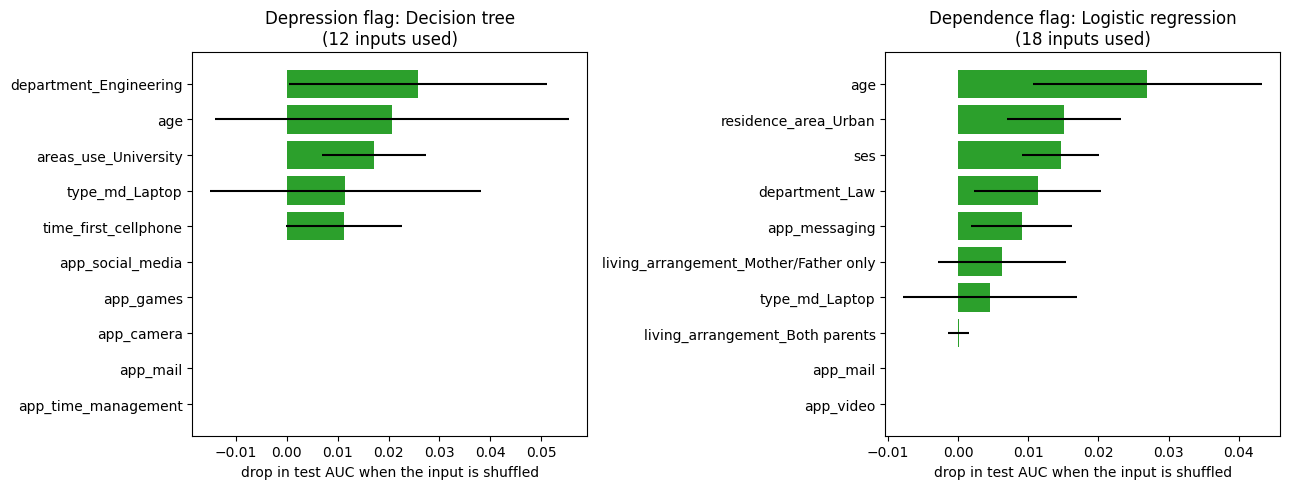

Near-duplicates dropped by the correlation filter (fitted on the full training set; the filter keeps the member of a pair that is more related to the target, so the list can differ by target):
  Dependence flag: areas_use_University, network_access_Wi-Fi, time_first_cellphone, type_md_Smartphone
  Depression flag: areas_use_Home, department_Health, network_access_Cellular data

Top 8 inputs for the final Depression flag model (Decision tree, Selected (correlation + importance)):


,input,auc_drop_mean,auc_drop_sd,used_by_model
12,department_Engineering,0.0258,0.0254,True
0,age,0.0207,0.0348,True
27,areas_use_University,0.0171,0.0102,True
28,type_md_Laptop,0.0115,0.0266,True
3,time_first_cellphone,0.0113,0.0115,True
6,app_social_media,0.0000,0.0000,False
5,app_games,0.0000,0.0000,True
10,app_camera,0.0000,0.0000,False



Top 8 inputs for the final Dependence flag model (Logistic regression, Selected (correlation + importance)):


,input,auc_drop_mean,auc_drop_sd,used_by_model
0,age,0.0270,0.0164,True
21,residence_area_Urban,0.0151,0.0081,True
2,ses,0.0146,0.0055,True
14,department_Law,0.0113,0.0091,True
4,app_messaging,0.0091,0.0072,True
17,living_arrangement_Mother/Father only,0.0062,0.0091,True
28,type_md_Laptop,0.0046,0.0124,True
16,living_arrangement_Both parents,0.0001,0.0015,True


In [9]:
imp_rows, sel_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (tname, tcol) in zip(axes, TARGETS.items()):
    ytr, yte = train[tcol].values, test[tcol].values
    variant, mname = FINAL[tname]
    best, thr = fitted[(tname, variant, mname)]
    sel = best.named_steps["sel"]

    # selector's view (only meaningful when the selector was active)
    if sel.importances_ is not None:
        for rank, (feat, v) in enumerate(sel.importances_.items(), 1):
            sel_rows.append({"target": tname, "model": mname, "rank": rank, "input": feat,
                             "forest_importance": v, "kept": feat in sel.cols_})
    # permutation importance on the test set (drop in AUC when one input is shuffled)
    pi = permutation_importance(best, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=1)
    s = pd.DataFrame({"input": APP_INPUTS, "auc_drop_mean": pi.importances_mean, "auc_drop_sd": pi.importances_std,
                      "used_by_model": [c in sel.cols_ for c in APP_INPUTS]}).sort_values("auc_drop_mean", ascending=False)
    s.insert(0, "target", tname); s.insert(1, "model", f"{mname} ({variant})")
    imp_rows.append(s)
    top = s.head(10)[::-1]
    ax.barh(top.input, top.auc_drop_mean, xerr=top.auc_drop_sd, color="tab:green")
    ax.set_title(f"{tname}: {mname}\n({sel.cols_.__len__()} inputs used)"); ax.set_xlabel("drop in test AUC when the input is shuffled")
plt.tight_layout(); plt.savefig(FIG / "appready_permutation_importance.png", dpi=130); plt.show()

imp_all = pd.concat(imp_rows); imp_all.round(4).to_csv(RES / "phase2_appready_permutation_importance.csv", index=False)
if sel_rows:
    pd.DataFrame(sel_rows).round(4).to_csv(RES / "phase2_appready_selector_importance.csv", index=False)

# which inputs does each "Selected" model keep? (fitted on the whole training set)
keep_rows = []
for (tname, variant, mname), (best, thr) in fitted.items():
    if variant.startswith("Selected") and not mname.startswith("Baseline"):
        sel = best.named_steps["sel"]
        keep_rows.append({"target": tname, "model": mname, "n_kept": len(sel.cols_),
                          "dropped_as_duplicates": ", ".join(sorted(set(APP_INPUTS) - set(sel.kept_after_corr_))),
                          "kept_inputs": ", ".join(sel.cols_)})
keep = pd.DataFrame(keep_rows); keep.to_csv(RES / "phase2_appready_selected_inputs.csv", index=False)
print("Near-duplicates dropped by the correlation filter (fitted on the full training set; the filter keeps the member of a pair that is more related to the target, so the list can differ by target):")
for t_, g in keep.groupby("target"):
    print(f"  {t_}: {g['dropped_as_duplicates'].iloc[0]}")
for tname in TARGETS:
    v, m = FINAL[tname]
    print(f"\nTop 8 inputs for the final {tname} model ({m}, {v}):")
    display(imp_all[imp_all.target == tname].head(8)[["input", "auc_drop_mean", "auc_drop_sd", "used_by_model"]].round(4))

## Step 6: What did "app-ready" cost us?

Members A and B scored models with the larger input list (F1), including family and phone-rule items the app cannot collect. Both ran the same 5 x 5 repeated cross-validation on the same training students, so the numbers are directly comparable.

,target,model,All app inputs,Selected (correlation + importance),A/B larger input list (F1),cost_of_app_only_inputs
1,Dependence flag,Decision tree,0.550,0.548,0.617,-0.067
2,Dependence flag,Gradient boosting,0.590,0.577,0.628,-0.038
3,Dependence flag,Logistic regression,0.602,0.595,0.644,-0.042
4,Dependence flag,Random forest,0.598,0.584,0.643,-0.045
6,Depression flag,Decision tree,0.611,0.610,0.596,0.015
7,Depression flag,Gradient boosting,0.610,0.611,0.615,-0.005
8,Depression flag,Logistic regression,0.593,0.590,0.603,-0.010
9,Depression flag,Random forest,0.618,0.613,0.634,-0.016


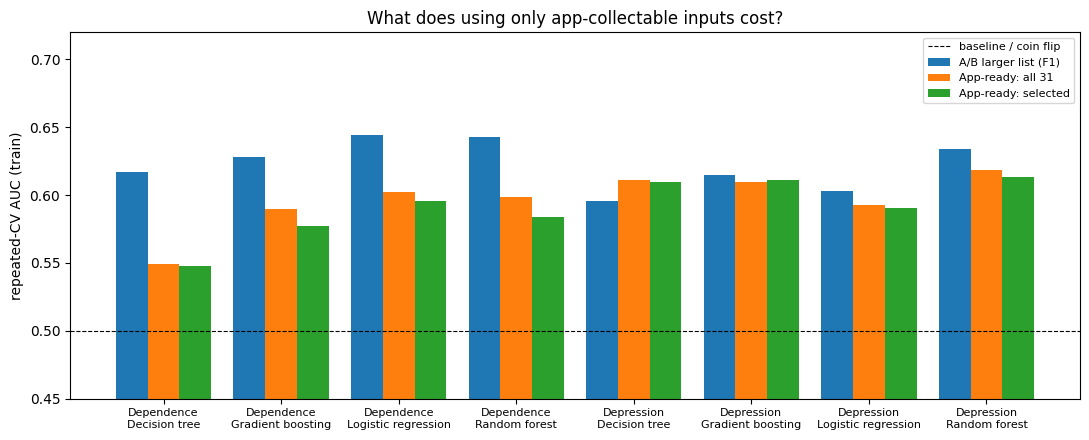

In [10]:
a = pd.read_csv(RES / "phase2_depression_repeated_cv.csv")
a = a[a.feature_set.str.startswith("F1")][["model", "repeated_cv_auc_mean"]].assign(target="Depression flag")
b = pd.read_csv(RES / "phase2_dependence_repeated_cv.csv")[["model", "repeated_cv_auc_mean"]].assign(target="Dependence flag")
f1 = pd.concat([a, b]).rename(columns={"repeated_cv_auc_mean": "A/B larger input list (F1)"})
mine = rep.pivot_table(index=["target", "model"], columns="inputs", values="repeated_cv_auc_mean").reset_index()
cmp_ = mine.merge(f1, on=["target", "model"], how="left")
cmp_["cost_of_app_only_inputs"] = cmp_["All app inputs"] - cmp_["A/B larger input list (F1)"]
cmp_ = cmp_[~cmp_.model.str.startswith("Baseline")]
cmp_.round(3).to_csv(RES / "phase2_appready_vs_F1.csv", index=False)
display(cmp_.round(3))

fig, ax = plt.subplots(figsize=(11, 4.5)); w = 0.27
lab = [f"{t.split()[0]}\n{m}" for t, m in zip(cmp_.target, cmp_.model)]; x = np.arange(len(cmp_))
ax.bar(x - w, cmp_["A/B larger input list (F1)"], w, label="A/B larger list (F1)")
ax.bar(x, cmp_["All app inputs"], w, label="App-ready: all 31")
ax.bar(x + w, cmp_["Selected (correlation + importance)"], w, label="App-ready: selected")
ax.axhline(0.5, color="black", ls="--", lw=0.8, label="baseline / coin flip")
ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=8); ax.set_ylim(0.45, 0.72); ax.set_ylabel("repeated-CV AUC (train)")
ax.set_title("What does using only app-collectable inputs cost?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "appready_vs_F1.png", dpi=130); plt.show()

## Step 7: Save everything for the team and for Phase 3

We save the test predictions (Member B uses them for the charts) and the **final model of each target** (Phase 3 turns these into Kotlin code). Loading the saved models needs `src/memberC_selector.py` to be importable, because the selector is part of the pipeline.

In [11]:
pr = test[["code"]].copy(); pr["depressed_flag"] = test["depressed_flag"].values; pr["dependence_flag"] = test["dependence_flag"].values
for (tname, variant, mname), (pte, cte) in test_pred.items():
    key = f"{tname.split()[0]}|{'all' if variant.startswith('All') else 'selected'}|{mname}"
    pr[f"{key}|prob"] = pte; pr[f"{key}|pred"] = cte
pr.round(4).to_csv(RES / "phase2_appready_test_predictions.csv", index=False)

joblib.dump({t: {"inputs": v, "model_name": m, "pipeline": fitted[(t, v, m)][0], "threshold": fitted[(t, v, m)][1],
                 "input_columns": APP_INPUTS}
             for t, (v, m) in FINAL.items()}, MOD / "phase2_appready_final_models.joblib")
print("Saved. Files now in results/ for this section:")
print(sorted(p.name for p in RES.glob("phase2_appready_*")))

Saved. Files now in results/ for this section:
['phase2_appready_confusion_matrices.csv', 'phase2_appready_feature_correlation_with_target.csv', 'phase2_appready_final_choice.csv', 'phase2_appready_permutation_check.csv', 'phase2_appready_permutation_importance.csv', 'phase2_appready_redundant_pairs.csv', 'phase2_appready_repeated_cv.csv', 'phase2_appready_results.csv', 'phase2_appready_selected_inputs.csv', 'phase2_appready_selector_importance.csv', 'phase2_appready_test_auc_ci.csv', 'phase2_appready_test_predictions.csv', 'phase2_appready_vs_F1.csv']


## Step 8: Findings in plain language (for the report and the presentation)

**1. Using only app-collectable inputs costs very little for depression, but a real amount for dependence.**
Compared with Members A and B (same 5 x 5 repeated CV, same students): the depression flag moves by between -0.016 and +0.015 AUC, which is smaller than the run-to-run noise (about 0.04). The dependence flag drops by 0.04 to 0.07 AUC (0.59 to 0.60 instead of about 0.64), which is larger than its noise (about 0.03). Plain reading: the family and phone-rule questions the app cannot ask were carrying some of the dependence signal. The app cannot get that back from its own inputs.

**2. Feature selection shrinks the input list without hurting.** The correlation filter removed 3 near-duplicates for depression and 4 for dependence (for example Wi-Fi vs cellular, "home" vs "university"). The importance filter then kept 8 to 18 inputs. Scores stayed within about 0.015 AUC of using all 31 inputs. *Analogy: a shorter questionnaire that gives about the same answer.* A shorter form is easier for students to fill in and easier to ship in the app.

**3. Every model is a weak screener. Please present it honestly.** Repeated-CV AUC is about 0.59 to 0.62 (0.5 is a coin flip, 1.0 is perfect). The shuffled-label check confirms the signal is real (about 0.60 against about 0.50 on shuffled answers, with a worst-case shuffle of about 0.56) but small. For depression, about 21 to 25 in 100 flagged students are truly flagged, against 18 in 100 if we flagged at random. The 95% ranges for test AUC are about plus or minus 0.09 and overlap between all models, so **we cannot claim one model is better than another**.

**4. Simple models were steadier.** Random forest and gradient boosting memorise the training set more (train-minus-test AUC gap 0.13 to 0.31) while logistic regression stays at 0.01 to 0.05, with similar scores.

**5. Which inputs matter?** Age, department, where the phone is used, residence area, income level and device type appear near the top, but each one only moves AUC by a few hundredths and the error bars are large. These are hints, not causes.

**6. Final app-ready models chosen by the pre-agreed rule:** depression flag, decision tree on 12 inputs; dependence flag, logistic regression on 18 inputs. For depression, six models tied within 0.01 AUC, so the rule picked the one with the fewest inputs. Logistic regression on 18 inputs is an equally defensible pick (test AUC 0.63, train-test gap 0.01); the team should decide, and Phase 3 can export either.

**Limits to state out loud:** screening flags from self-report questionnaires, not diagnoses; one university sample of 1,220 students; weak signal (AUC about 0.6); test set of 244 students (43 depression-flagged), so scores are rough.